# Pharmaceutical R&D valuation under regulatory uncertainty

How much is a drug-development project worth when development can fail, the investor can abandon it, and regulation can change its commercial returns? This notebook explores that question using Monte Carlo simulation and a least-squares estimate of the decision to continue investing.

The project passes through three R&D phases, an approval delay and a protected commercial period. We compare the base case with two regulatory events: shorter protection and lower cash flows. Sensitivity analysis varies the economic assumptions; valuation isolines identify combinations of protection and cash flow that produce the same project value.

First read the parameter table, then run Sections 1–3 in order. Sections 4–5 contain longer optional experiments. Section 6 now performs numerical diagnostics.

**Units:** money is in USD million, cash flows and spending rates are annual, and time is in years. The base-case technical-failure probability is 0.0091 per month.


In [33]:
from pathlib import Path
import json, gc, platform, hashlib, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from scipy.stats import t as student_t
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from IPython.display import display


## 1 Parameters and execution settings

`BASE` defines the calibration used throughout this notebook. 

`n_simulations` controls the number of simulated projects; the saved results use 100,000. Seeds make the displayed run reproducible.

Flags enable reproduce the full sensitivity curves or isoline surface. Those grids can take more time.


In [34]:
CALIBRATION = 'base_case'  # Monthly technical-failure probability: 0.0091
# Central economic and simulation assumptions.
BASE = {
    'n_simulations': 100000,  # Number of simulated development histories
    'T': 25,  # Development horizon, years
    'dt': 0.08333333333333333,  # Decision interval, years (monthly)
    'C0': 20,  # Initial annual net cash-flow estimate, USD million/year
    'K10': 13.76,  # Phase I remaining cost, USD million
    'K20': 31.04,  # Phase II remaining cost, USD million
    'K30': 115.2,  # Phase III remaining cost, USD million
    'alpha_star_I': 0.022,  # Annual drift of cash-flow estimates during development
    'I1': 8.6,  # Phase I spending, USD million/year
    'I2': 10.7,  # Phase II spending, USD million/year
    'I3': 30.3,  # Phase III spending, USD million/year
    'sigma_C': 0.3,  # Annual volatility of cash-flow estimates
    'sigma_K1': 0.343,  # Phase I cost-uncertainty parameter
    'sigma_K2': 0.406,  # Phase II cost-uncertainty parameter
    'sigma_K3': 0.343,  # Phase III cost-uncertainty parameter
    'r': 0.04,  # Annual discount rate
    'lambda_1': 0.0091,  # Monthly technical-failure probability
    'lambda_2': 0.0,  # Regulatory-event probability; zero in the base case
    'tau_vs_tau3': 1.5,  # Approval lag after phase III, years
    'alpha_star_P': 0.15,  # Annual commercial cash-flow growth rate
    'YearPatent': 10,  # Protected commercial years in the base case
    'YearRegulatory': 8,  # Protected years if a duration event occurs
    'CashflowRedctionRegulatory': 0.7,  # Fraction RETAINED after a cash-flow event
    'TypeRegulatory': 'Cashflow',  # Event type: Cashflow or Duration
}
RUN_SENSITIVITY = True
RUN_ISOLINES = True
PATH_SEED, EVENT_SEED = 42, 50
OUT = Path('results') / CALIBRATION
OUT.mkdir(parents=True, exist_ok=True)
# A fresh copy is restored before every independent experiment.
globals().update(BASE)
manifest = dict(calibration=CALIBRATION, parameters=BASE, path_seed=PATH_SEED, event_seed=EVENT_SEED,
                python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                scipy=scipy.__version__, sklearn=sklearn.__version__)
(OUT / 'configuration.json').write_text(json.dumps(manifest, indent=2))
display(pd.Series(BASE, name='Value').to_frame())


,Value
n_simulations,100000
T,25
dt,0.083333
C0,20
K10,13.76
K20,31.04
K30,115.2
alpha_star_I,0.022
I1,8.6
I2,10.7


## 2 Simulation and valuation functions

`simulate_paths` generates cash-flow estimates, remaining development costs and phase-completion dates. `Vtau3` values the commercial cash-flow stream after phase III. `PVcosts` discounts the spending incurred before completion or stopping. `valuation_procedure` combines these elements with technical failure, regulatory risk and the decision to abandon.

The continuation decision is estimated separately at each date with a quadratic regression on cash flow and remaining costs. Each function below documents its inputs, units, outputs and numerical assumptions. The helpers that follow reset parameters and assemble summary statistics.

The implementation has finite-horizon and time-zero conventions that matter for numerical interpretation. These are described in the function notes and the README; the numerical diagnostics quantify simulation variation but do not eliminate approximation bias.


In [35]:
def simulate_paths(C0, K10, K20, K30, alpha, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations, seed=42):
    """Simulate cash-flow estimates and remaining costs through three R&D phases.

    Each path represents one possible development history. Cash-flow estimates
    follow an Euler approximation to geometric Brownian motion. Remaining costs
    have square-root diffusion; only the currently funded phase incurs spending.
    Future-phase costs can fluctuate before that phase starts.

    Parameters
    ----------
    C0 : float
        Initial annual net cash-flow estimate if commercialized, in USD million.
    K10, K20, K30 : float
        Initial remaining development costs by phase, in USD million.
    alpha : float
        Annual drift of the cash-flow estimate during development.
    I1, I2, I3 : float
        Annual spending rates during each phase, in USD million per year.
    sigma_C : float
        Annual cash-flow volatility.
    sigma_K1, sigma_K2, sigma_K3 : float
        Parameters controlling uncertainty in phase development costs.
    r : float
        Annual discount rate. Included for interface consistency; not used here.
    T, dt : float
        Development horizon and time step, in years. The grid ends at T - dt.
    n_simulations : int
        Number of simulated paths.
    seed : int, optional
        Seed for reproducible random draws, where exposed by the signature.

    Returns
    -------
    C, K1, K2, K3 : ndarray, shape (n_simulations, int(T / dt))
        Cash-flow estimates and remaining-cost states on the time grid.
    t : ndarray
        Decision dates in years.
    tau_1, tau_2, tau_3 : ndarray, shape (n_simulations,)
        Recorded completion dates for the three phases.

    Notes
    -----
    A negative raw active-phase cost update records phase completion. Costs are
    then floored at zero to prevent invalid square roots in later steps.
    Unfinished phases retain the final date as their completion-time sentinel;
    this convention requires care when interpreting horizon effects.
    """
    np.random.seed(seed)
    # Allocate one row per path and one column per decision date.
    n_steps = int(T / dt)
    C = np.zeros((n_simulations, n_steps))
    K1 = np.zeros((n_simulations, n_steps))
    K2 = np.zeros((n_simulations, n_steps))
    K3 = np.zeros((n_simulations, n_steps))
    t = np.linspace(0, T - dt, n_steps)
    C[:, 0] = C0
    K1[:, 0] = K10
    K2[:, 0] = K20
    K3[:, 0] = K30
    # Initialize completion times to the final date until a phase crosses zero.
    tau_1 = np.ones((1, n_simulations))[0] * (T - dt)
    tau_2 = np.ones((1, n_simulations))[0] * (T - dt)
    tau_3 = np.ones((1, n_simulations))[0] * (T - dt)
    for i in range(1, n_steps):
        # Independent standard-normal shocks drive cash flow and the three costs.
        dW_C = np.random.normal(0, 1, n_simulations)
        dW_K1 = np.random.normal(0, 1, n_simulations)
        dW_K2 = np.random.normal(0, 1, n_simulations)
        dW_K3 = np.random.normal(0, 1, n_simulations)
        # Build phase masks before updates; the next phase spends from the next step.
        actStage1 = np.where(t[i] < tau_1)[0]
        actStage2 = np.where(t[i] <= tau_2)[0]
        actStage3 = np.where(t[i] <= tau_3)[0]
        actStage12 = np.where((t[i] >= tau_1) & (t[i] <= tau_2))[0]
        actStage23 = np.where((t[i] >= tau_2) & (t[i] <= tau_3))[0]
        # Euler cash-flow update, with a nonnegative boundary.
        C[:, i] = C[:, i - 1] + (alpha * dt + sigma_C * dt ** 0.5 * dW_C) * C[:, i - 1]
        C[:, i] = np.where(C[:, i] < 0, 0, C[:, i])
        # Active phases spend Ij*dt; pending-phase costs diffuse without spending.
        K1[actStage1, i] = K1[actStage1, i - 1] - I1 * dt + sigma_K1 * dt ** 0.5 * (I1 * K1[actStage1, i - 1]) ** 0.5 * dW_K1[actStage1]
        K2[actStage1, i] = K2[actStage1, i - 1] - 0 * dt + sigma_K2 * dt ** 0.5 * (I2 * K2[actStage1, i - 1]) ** 0.5 * dW_K2[actStage1]
        K2[actStage12, i] = K2[actStage12, i - 1] - I2 * dt + sigma_K2 * dt ** 0.5 * (I2 * K2[actStage12, i - 1]) ** 0.5 * dW_K2[actStage12]
        K3[actStage1, i] = K3[actStage1, i - 1] - 0 * dt + sigma_K3 * dt ** 0.5 * (I3 * K3[actStage1, i - 1]) ** 0.5 * dW_K3[actStage1]
        K3[actStage12, i] = K3[actStage12, i - 1] - 0 * dt + sigma_K3 * dt ** 0.5 * (I3 * K3[actStage12, i - 1]) ** 0.5 * dW_K3[actStage12]
        K3[actStage23, i] = K3[actStage23, i - 1] - I3 * dt + sigma_K3 * dt ** 0.5 * (I3 * K3[actStage23, i - 1]) ** 0.5 * dW_K3[actStage23]
        # Record negative active-cost crossings BEFORE flooring the costs.
        if len(np.where(K1[actStage1, i] < 0)[0]) > 0:
            tau_1[actStage1] = np.where(K1[actStage1, i] < 0, t[i], tau_1[actStage1])
        if len(np.where(K2[actStage12, i] < 0)[0]) > 0:
            tau_2[actStage12] = np.where(K2[actStage12, i] < 0, t[i], tau_2[actStage12])
            tau_1[actStage1] = np.where(tau_2[actStage1] < tau_1[actStage1], tau_2[actStage1], tau_1[actStage1])
        if len(np.where(K3[actStage23, i] < 0)[0]) > 0:
            tau_3[actStage23] = np.where(K3[actStage23, i] < 0, t[i], tau_3[actStage23])
            tau_2[actStage12] = np.where(tau_3[actStage12] < tau_2[actStage12], tau_3[actStage12], tau_2[actStage12])
            tau_1[actStage1] = np.where(tau_2[actStage1] < tau_1[actStage1], tau_2[actStage1], tau_1[actStage1])
        # Keep all remaining costs nonnegative for the next square-root update.
        K1[:, i] = np.maximum(K1[:, i], 0.0)
        K2[:, i] = np.maximum(K2[:, i], 0.0)
        K3[:, i] = np.maximum(K3[:, i], 0.0)
    return (C, K1, K2, K3, t, tau_1, tau_2, tau_3)




def PVcosts(I1, I2, I3, r, t0, tau_1, tau_2, tend):
    # Integrate spending only over phases reached before the stopping date.
    """Discount development spending accumulated up to a stopping date.

    Spending occurs at constant annual rates I1, I2 and I3 in consecutive phases.
    Each phase interval is integrated analytically and truncated at tend.

    Parameters
    ----------
    I1, I2, I3 : float
        Phase spending rates, in USD million per year.
    r : float
        Positive annual discount rate.
    t0 : float
        Initial date; the valuation workflow uses zero.
    tau_1, tau_2 : float
        Phase I and II completion dates, in years.
    tend : float
        Failure, abandonment or final development-completion date.

    Returns
    -------
    float
        Present value of spending, in USD million.
    """
    if tend < tau_1:
        PVC = I1 / r * (1 - np.exp(-r * (tend - t0)))
    elif tend < tau_2:
        PVC = I1 / r * (1 - np.exp(-r * (tau_1 - t0))) + I2 / r * (1 - np.exp(-r * (tend - tau_1))) * np.exp(-r * tau_1)
    else:
        PVC = I1 / r * (1 - np.exp(-r * (tau_1 - t0))) + I2 / r * (1 - np.exp(-r * (tau_2 - tau_1))) * np.exp(-r * tau_1) + I3 / r * (1 - np.exp(-r * (tend - tau_2))) * np.exp(-r * tau_2)
    return PVC



def Vtau3(C, r, alpha_star_P, Year, tau_vs_tau3):
    # Discount the growing protected-period cash-flow stream.
    """Value commercial cash flows at completion of phase III.

    The project earns no cash flow during the approval lag. It then earns an
    exponentially growing annual net cash flow for Year protected years, plus
    an expiry terminal value equal to five times the final annual cash flow.
    Both components are discounted back to phase III completion.

    Parameters
    ----------
    C : float or ndarray
        Annual cash-flow level at commercialization, in USD million per year.
    r : float
        Annual discount rate.
    alpha_star_P : float
        Annual commercial cash-flow growth rate.
    Year : float
        Number of protected commercial years.
    tau_vs_tau3 : float
        Approval lag after phase III completion, in years.

    Returns
    -------
    float or ndarray
        Commercial value at phase III completion, in USD million.

    Notes
    -----
    This closed form requires alpha_star_P != r. If the rates are equal, the
    protected-period integral must be replaced by its limiting expression.
    The subsequent valuation step discounts this value from tau_3 to time zero.
    """
    if alpha_star_P <= r:
        value = C / (r - alpha_star_P) * (1 - np.exp(-(r - alpha_star_P) * Year)) * np.exp(-r * tau_vs_tau3)
    else:
        value = C / (alpha_star_P - r) * (np.exp((alpha_star_P - r) * Year) - 1) * np.exp(-r * tau_vs_tau3)
    # This intermediate expiry cash flow is already discounted over the protected years.
    C_end = C * np.exp((alpha_star_P - r) * Year)
    # Add five times expiry cash flow and discount the approval lag.
    residual_value = 5 * C_end * np.exp(-r * tau_vs_tau3)
    value += residual_value
    return value



def valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2, seed=50):
    # Use a separate seed for regulatory and technical-failure draws.
    """Estimate the abandonment policy and account for pathwise project payoffs.

    At each development date, a pooled quadratic regression estimates discounted
    continuation value from cash flow and remaining phase costs. Development
    continues when that estimate exceeds the next step's spending. Technical
    failure and regulatory-event draws are included in the valuation.

    Parameters
    ----------
    K1, K2, K3, C : ndarray, shape (number of paths, number of dates)
        Simulated states returned by simulate_paths.
    t : ndarray
        Development decision dates, in years.
    tau_1, tau_2, tau_3 : ndarray
        Recorded phase-completion dates for each path.
    tau_vs_tau3 : float
        Approval lag after phase III, in years.
    dt : float
        Time step, in years.
    lambda_1 : float
        Technical-failure probability PER STEP, not an annual intensity.
        At monthly steps this equals the monthly failure probability.
    lambda_2 : float
        Probability of the regulatory event at commercialization.
    r, alpha_star_P : float
        Annual discount rate and commercial cash-flow growth rate.
    YearPatent, YearRegulatory : float
        Protected commercial years without and with a duration event.
    CashflowRedctionRegulatory : float
        Fraction of cash flow RETAINED if a cash-flow event occurs (e.g. 0.70).
    TypeRegulatory : str
        'Duration' for changed protection; otherwise a cash-flow change.
    Poly_deg : int, optional
        Polynomial degree; 2 includes squares and pairwise interactions.
    seed : int, optional
        Seed for valuation/event draws, where exposed by the signature.

    Returns
    -------
    F2 : ndarray, shape (number of paths, number of dates)
        Backward values used to estimate continuation decisions.
    F0 : ndarray, shape (number of paths, 1)
        Realized discounted project payoffs after the earliest stopping event.
    regulatory : ndarray, shape (number of paths,)
        Indicators of regulatory-event draws.
    catastrophic, discontinued : ndarray
        Technical-failure and abandonment flags by path and date.

    Notes
    -----
    Reads phase spending rates I1, I2 and I3 from notebook globals. The runner
    sets these before calling the function; use serial execution.
    Policy fitting and evaluation use the same paths. At time zero, the code
    uses the mean next-step value without the positive-date discount factor.
    F0 is computed separately using discounted commercial value and integrated
    spending; it is not the initial fitted F2 value. A tie between failure and
    abandonment is classified as abandonment in the reported stopping rate.
    """
    np.random.seed(seed)
    Tamx = np.max(tau_3)
    iTmax = np.where(t == Tamx)[0][0]
    (n_simulations, n_steps) = K1.shape
    F2 = np.zeros((n_simulations, n_steps))
    regulatory = np.zeros(n_simulations)
    catastrophic = np.zeros((n_simulations, n_steps))
    discontinued = np.zeros((n_simulations, n_steps))
    V = np.zeros((n_simulations, n_steps))
    # Initialize each path with commercial value at its phase III completion date.
    for i in range(n_simulations):
        it_tau3 = np.where(tau_3[i] == t)[0][0]
        if np.random.rand() > lambda_2:
            V[i, it_tau3] = Vtau3(C[i, it_tau3], r, alpha_star_P, YearPatent, tau_vs_tau3)
            (F2[i, it_tau3], regulatory[i]) = (V[i, it_tau3], 0)
        else:
            if TypeRegulatory == 'Duration':
                V[i, it_tau3] = Vtau3(C[i, it_tau3], r, alpha_star_P, YearRegulatory, tau_vs_tau3)
            else:
                V[i, it_tau3] = Vtau3(C[i, it_tau3] * CashflowRedctionRegulatory, r, alpha_star_P, YearPatent, tau_vs_tau3)
            (F2[i, it_tau3], regulatory[i]) = (V[i, it_tau3], 1)
    # Work backward through development dates to estimate continuation decisions.
    for it in range(iTmax - 1, -1, -1):
        # Pool every path still in development at this date, across all phases.
        active = tau_3 > t[it]
        stage2 = (tau_1 <= t[it]) & (tau_2 > t[it])
        stage1 = tau_1 > t[it]
        if np.any(active):
            if it != 0:
                # Quadratic OLS uses cash flow and all three remaining-cost states.
                X = np.column_stack((C[active, it], K3[active, it], K2[active, it], K1[active, it]))
                Y = F2[active, it + 1] * np.exp(-r * dt)
                N = Poly_deg
                poly = PolynomialFeatures(degree=N)
                X_poly = poly.fit_transform(X)
                model = LinearRegression()
                model.fit(X_poly, Y)
                discounted_expected_val = model.predict(X_poly)
            else:
                # At time zero all initial states coincide; this branch omits step discounting.
                discounted_expected_val = np.repeat(np.mean(F2[active, it + 1]), np.sum(active))
            # Select the spending rate for the currently active development phase.
            Investment = np.where(stage1[active], I1, np.where(stage2[active], I2, I3))
            F2[active, it] = np.where(discounted_expected_val > Investment * dt, discounted_expected_val - Investment * dt, 0)
            discontinued[active, it] = np.where(discounted_expected_val > Investment * dt, 0, 1)
        # Apply technical failure after the continuation/abandonment comparison.
        possible_catastrophic = tau_3 > t[it]
        if np.any(possible_catastrophic):
            realized_catastrophic = np.random.rand(np.sum(possible_catastrophic)) < lambda_1
            if np.any(realized_catastrophic):
                F2[possible_catastrophic, it] = np.where(realized_catastrophic, 0, F2[possible_catastrophic, it])
                catastrophic[possible_catastrophic, it] = np.where(realized_catastrophic, 1, 0)
    
    # Account for final payoffs chronologically, separately from fitted values.
    F0 = np.zeros((n_simulations, 1))
    for i in range(n_simulations):
        # The earliest failure or abandonment determines how much spending is incurred.
        first_catastrophic = np.where(catastrophic[i, :] == 1)[0]
        first_discontinuance = np.where(discontinued[i, :] == 1)[0]
        if len(first_catastrophic) > 0 and len(first_discontinuance) > 0:
            if first_catastrophic[0] < first_discontinuance[0]:
                F0[i] = 0 - PVcosts(I1, I2, I3, r, t[0], tau_1[i], tau_2[i], t[first_catastrophic[0]])
            else:
                F0[i] = 0 - PVcosts(I1, I2, I3, r, t[0], tau_1[i], tau_2[i], t[first_discontinuance[0]])
        elif len(first_catastrophic) > 0:
            F0[i] = 0 - PVcosts(I1, I2, I3, r, t[0], tau_1[i], tau_2[i], t[first_catastrophic[0]])
        elif len(first_discontinuance) > 0:
            F0[i] = 0 - PVcosts(I1, I2, I3, r, t[0], tau_1[i], tau_2[i], t[first_discontinuance[0]])
        elif regulatory[i] == 1:
            it_tau3 = np.where(tau_3[i] == t)[0][0]
            F0[i] = V[i, it_tau3] * np.exp(-r * tau_3[i]) - PVcosts(I1, I2, I3, r, t[0], tau_1[i], tau_2[i], tau_3[i])
        else:
            it_tau3 = np.where(tau_3[i] == t)[0][0]
            F0[i] = V[i, it_tau3] * np.exp(-r * tau_3[i]) - PVcosts(I1, I2, I3, r, t[0], tau_1[i], tau_2[i], tau_3[i])
    return (F2, F0, regulatory, catastrophic, discontinued)


In [36]:
PARAMETER_ORDER = ['n_simulations', 'T', 'dt', 'C0', 'K10', 'K20', 'K30', 'alpha_star_I', 'I1', 'I2', 'I3', 'sigma_C', 'sigma_K1', 'sigma_K2', 'sigma_K3', 'r', 'lambda_1', 'lambda_2', 'tau_vs_tau3', 'alpha_star_P', 'YearPatent', 'YearRegulatory', 'CashflowRedctionRegulatory', 'TypeRegulatory']

def init_sensitivity():
    """Return fresh base-case parameters in the order used by sensitivity loops.

    Resetting before each experiment prevents one parameter sweep from changing
    the starting assumptions of the next. BASE itself is not modified.
    """
    return tuple(BASE[name] for name in PARAMETER_ORDER)

def summarize_values(values, catastrophic=None, discontinued=None):
    """Summarize pathwise project values and the realized abandonment rate.

    Values and quantiles are in USD million; probability outputs are proportions.
    When event arrays are supplied, abandonment means an abandonment flag occurs
    before or at the first technical failure. Potential later flags are ignored.
    """
    f=np.asarray(values).ravel()
    row={'mean':f.mean(),'median':np.median(f),'p05':np.quantile(f,.05),
         'p95':np.quantile(f,.95),'p99':np.quantile(f,.99),'maximum':f.max(),
         'share_above_1bn':np.mean(f>1000)}
    if catastrophic is not None:
        has_cat=catastrophic.any(axis=1)
        has_dis=discontinued.any(axis=1)
        row['abandonment_rate']=np.mean(has_dis & (~has_cat | (discontinued.argmax(axis=1) <= catastrophic.argmax(axis=1)))) #Percentage of only discontinued or discontinued first
        row['catastrophic_rate']=np.mean(has_cat & (~has_dis | (catastrophic.argmax(axis=1) < discontinued.argmax(axis=1)))) #Percentage of only catastrophic or catastrophic first
        row['failure_rate']=np.mean(has_cat | has_dis) #Percentage of both catastrophic or discontinued, i.e., the total failure rate
    return row

def run_case(overrides=None, paths=None):
    """Run one parameter scenario, optionally reusing simulated development paths.

    Overrides are applied to a copy of BASE. Reuse paths only when changing
    commercial or regulatory assumptions, not development-process parameters.
    Sets spending-rate globals consistently before valuation and returns a
    statistics dictionary plus a one-dimensional copy of project payoffs.
    """
    p=BASE.copy();p.update(overrides or {})
    globals().update({k:p[k] for k in ('I1','I2','I3')})
    if paths is None:
        paths=simulate_paths(*[p[k] for k in ('C0','K10','K20','K30','alpha_star_I','I1','I2','I3','sigma_C','sigma_K1','sigma_K2','sigma_K3','r','T','dt','n_simulations')],seed=PATH_SEED)
    C,K1,K2,K3,t,tau_1,tau_2,tau_3=paths
    if not all(np.isfinite(x).all() for x in (C,K1,K2,K3)):
        raise ValueError('Nonfinite simulated states')
    F2,F0,reg,cat,dis=valuation_procedure(K1,K2,K3,C,t,tau_1,tau_2,tau_3,p['tau_vs_tau3'],p['dt'],p['lambda_1'],p['lambda_2'],p['r'],p['alpha_star_P'],p['YearPatent'],p['YearRegulatory'],p['CashflowRedctionRegulatory'],p['TypeRegulatory'],seed=EVENT_SEED)
    if not np.isfinite(F0).all():raise ValueError('Nonfinite project values')
    return summarize_values(F0,cat,dis),F0.ravel().copy()


## 3 Base case and regulatory scenarios
Event I has probability 0.2 and reduces protected duration from 10 to 8 years. Event II has probability 0.2 and retains 70% of cash flows. Development paths and valuation seeds are shared across scenarios. Technical-failure risk remains in every case.

,scenario,mean,median,p05,p95,p99,maximum,share_above_1bn,abandonment_rate,catastrophic_rate,failure_rate
0,Base case,145.558034,-10.485674,-109.348007,881.615477,1848.644020,21982.472879,0.0401,0.02393,0.58167,0.60560
1,Regulatory event I,134.607401,-11.166253,-109.403074,835.899101,1758.648173,21982.472879,0.0360,0.02622,0.58069,0.60691
2,Regulatory event II,132.493687,-11.166253,-109.433942,825.649992,1747.356441,21982.472879,0.0353,0.02663,0.58052,0.60715


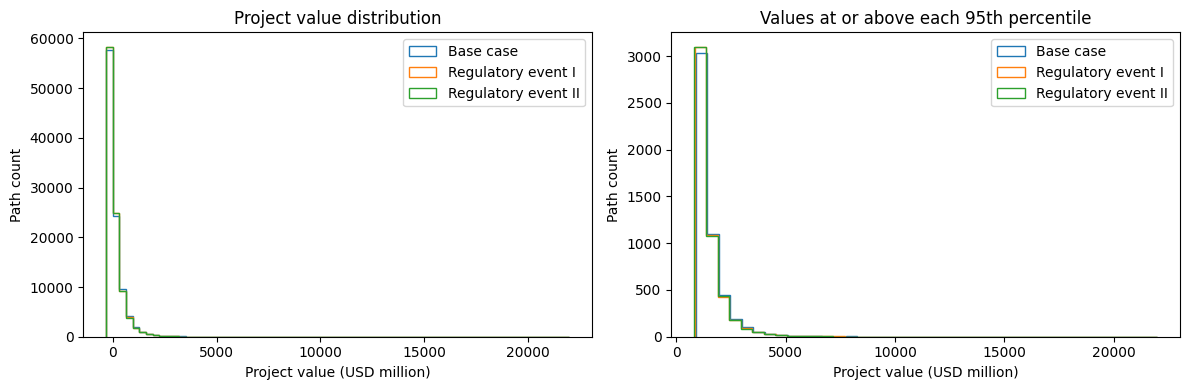

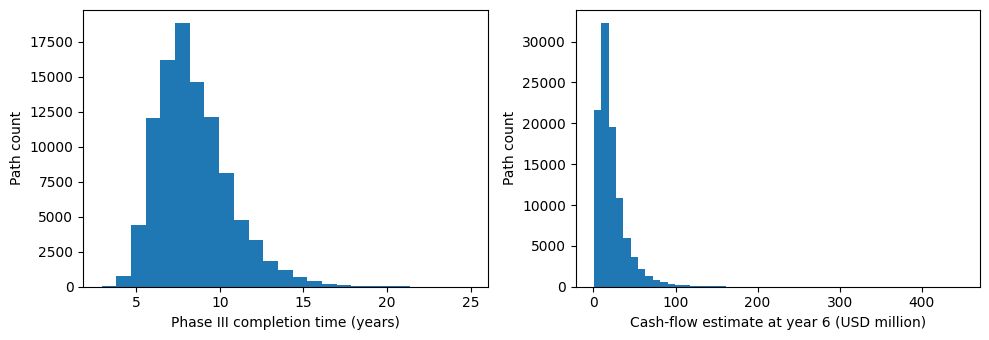

16161

In [37]:
# Run the base case and two regulatory-event scenarios, reusing the same development paths.
paths=simulate_paths(*[BASE[k] for k in ('C0','K10','K20','K30','alpha_star_I','I1','I2','I3','sigma_C','sigma_K1','sigma_K2','sigma_K3','r','T','dt','n_simulations')],seed=PATH_SEED)
CASES={'Base case':dict(lambda_2=0.0),
       'Regulatory event I':dict(lambda_2=0.2,TypeRegulatory='Duration',YearRegulatory=8),
       'Regulatory event II':dict(lambda_2=0.2,TypeRegulatory='Cashflow',YearRegulatory=10,CashflowRedctionRegulatory=0.70)}
# Run each scenario, summarize the results, and save a CSV of the statistics.
rows=[]; project_values={}
for case, changes in CASES.items():
    stats,values=run_case(changes,paths)
    rows.append(dict(scenario=case,**stats));project_values[case]=values
scenario_results=pd.DataFrame(rows)
scenario_results.to_csv(OUT/'scenario_summary.csv',index=False)
# Display the scenario summary and plot the project-value distributions.
display(scenario_results)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,values in project_values.items():
    axes[0].hist(values,bins=70,histtype='step',label=name)
    tail=values[values>=np.quantile(values,.95)]
    axes[1].hist(tail,bins=40,histtype='step',label=name)
for ax in axes:
    ax.set_xlabel('Project value (USD million)');ax.set_ylabel('Path count');ax.legend()
axes[0].set_title('Project value distribution');axes[1].set_title('Values at or above each 95th percentile')
fig.tight_layout();fig.savefig(OUT/'project_value_distributions.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].hist(paths[-1],bins=25);axes[0].set_xlabel('Phase III completion time (years)')
axes[1].hist(paths[0][:,int(6/BASE['dt'])],bins=50);axes[1].set_xlabel('Cash-flow estimate at year 6 (USD million)')
for ax in axes:ax.set_ylabel('Path count')
fig.tight_layout();plt.show()
del paths;gc.collect()


## 4 Sensitivity of project value to model parameters

These experiments vary one parameter or a defined set of related parameters while holding the other assumptions fixed. Set `RUN_SENSITIVITY=True` in Section 1 to calculate the curves. Every loop starts from the same base-case parameters.

The total-cost experiment also rescales spending rates to preserve the initial expected phase durations. Some plots floor negative mean values at zero; this is a reporting convention, identified in the code, and is not applied to the base-case summary.


### Initial cash flow

,Initial Cash flow,case,Project Value [F0]
0,5.0,Base Case,0.000000
1,5.0,Reg Event I,0.000000
2,5.0,Reg Event II,0.000000
3,8.0,Base Case,17.349039
4,8.0,Reg Event I,13.585903
5,8.0,Reg Event II,12.863899
6,11.0,Base Case,48.263571
7,11.0,Reg Event I,42.441564
8,11.0,Reg Event II,41.306158
9,14.0,Base Case,80.365541


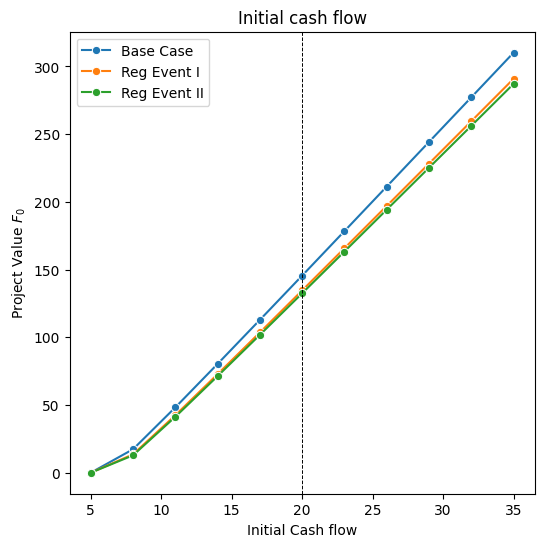

In [38]:
if RUN_SENSITIVITY:
    import pandas as pd
    # Change the starting commercial opportunity while holding development costs fixed.
    C0_values = np.linspace(5, 35, 11)
    Cases = ['Base Case', 'Reg Event I', 'Reg Event II']
    results = []
    (n_simulations, T, dt, C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, lambda_1, lambda_2, tau_vs_tau3, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory) = init_sensitivity()
    for C0 in C0_values:
        for case in Cases:
            if case == 'Base Case':
                lambda_2 = 0.0
                TypeRegulatory = 'Cashflow'
            elif case == 'Reg Event I':
                lambda_2 = 0.2
                TypeRegulatory = 'Duration'
            elif case == 'Reg Event II':
                lambda_2 = 0.2
                TypeRegulatory = 'Cashflow'
            (C, K1, K2, K3, t, tau_1, tau_2, tau_3) = simulate_paths(C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations)
            (F2, F0, regulatory, catastrophic, discontinued) = valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2)
            results.append({'Initial Cash flow': C0, 'case': case, 'Project Value [F0]': F0.mean() if F0.mean() > 0 else 0})
    results = pd.DataFrame(results)
    results
    import seaborn as sns
    plt.figure(figsize=(6, 6))
    sns.lineplot(data=results, x='Initial Cash flow', y='Project Value [F0]', hue='case', marker='o')
    plt.legend(title=None)
    plt.ylabel('Project Value $F_0$')
    plt.axvline(20, color='black', linestyle='--', linewidth=0.7)
    plt.title('Initial cash flow')
    results.to_csv(OUT / 'initial_cashflow.csv', index=False)
    display(results)
    plt.show()
else:
    print("Skipped optional sensitivity grid: Initial cash flow.")


### Technical-failure probability

,lambda_1,case,F0
0,0.006100,A,205.532258
1,0.006100,B,190.810110
2,0.006100,C,187.965068
3,0.007957,A,166.033676
4,0.007957,B,153.825669
5,0.007957,C,151.475165
6,0.009814,A,134.203149
7,0.009814,B,123.938560
8,0.009814,C,121.957388
9,0.011671,A,107.782190


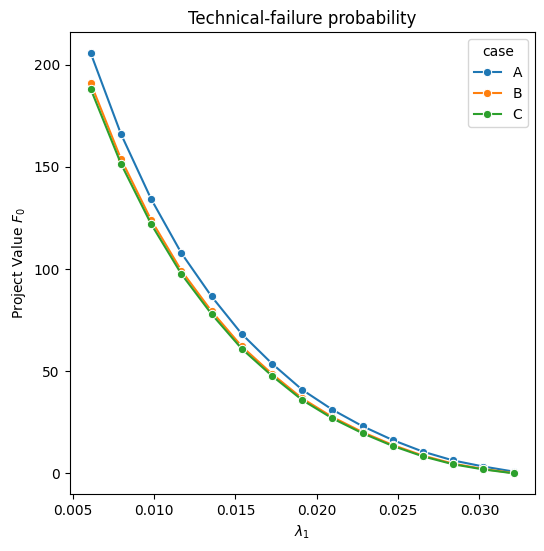

In [41]:
if RUN_SENSITIVITY:
    import pandas as pd
    # Build the failure-risk grid; values passed to valuation are monthly probabilities.
    lambda_1_values = np.linspace(0.0061, 0.0321, 15) * 12
    Cases = ['A', 'B', 'C']
    results = []
    (n_simulations, T, dt, C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, lambda_1, lambda_2, tau_vs_tau3, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory) = init_sensitivity()
    for lambda_1 in lambda_1_values:
        lambda_1 = lambda_1 / 12
        for case in Cases:
            if case == 'A':
                lambda_2 = 0.0
                TypeRegulatory = 'Cashflow'
            elif case == 'B':
                lambda_2 = 0.2
                TypeRegulatory = 'Duration'
            elif case == 'C':
                lambda_2 = 0.2
                TypeRegulatory = 'Cashflow'
            (C, K1, K2, K3, t, tau_1, tau_2, tau_3) = simulate_paths(C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations)
            (F2, F0, regulatory, catastrophic, discontinued) = valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2)
            results.append({'lambda_1': lambda_1, 'case': case, 'F0': F0.mean()})
    results = pd.DataFrame(results)
    results
    import seaborn as sns
    plt.figure(figsize=(6, 6))
    sns.lineplot(data=results, x='lambda_1', y='F0', hue='case', marker='o')
    plt.ylabel('Project Value $F_0$')
    plt.xlabel('$\\lambda_1$')
    plt.title('Technical-failure probability')
    results.to_csv(OUT / 'technical_failure.csv', index=False)
    display(results)
    plt.show()
else:
    print("Skipped optional sensitivity grid: Technical-failure probability.")


### Total development cost

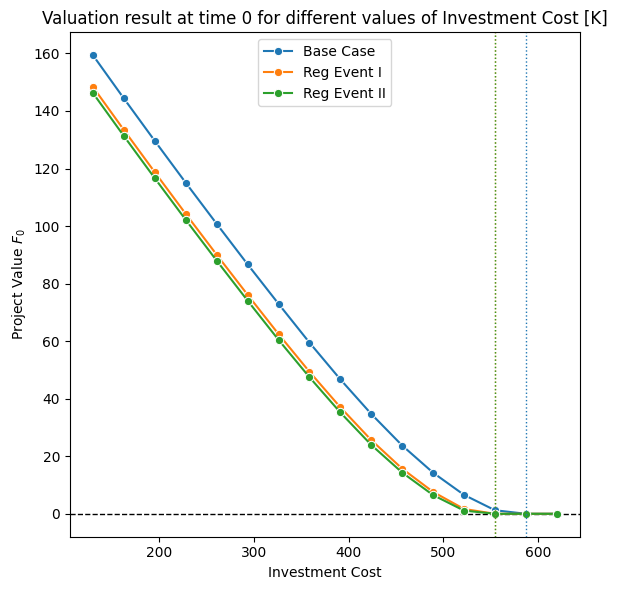

,Investment Cost [K],case,Project Value [F0]
0,130.000000,Base Case,159.358887
1,130.000000,Reg Event I,148.335724
2,130.000000,Reg Event II,146.217861
3,162.666667,Base Case,144.346076
4,162.666667,Reg Event I,133.396144
5,162.666667,Reg Event II,131.281986
6,195.333333,Base Case,129.585704
7,195.333333,Reg Event I,118.706816
8,195.333333,Reg Event II,116.606641
9,228.000000,Base Case,115.052486


In [42]:
if RUN_SENSITIVITY:
    import pandas as pd
    # Scale total costs and spending together to preserve expected phase durations.
    Total_K_values = np.linspace(130, 620, 16)
    Cases = ['Base Case', 'Reg Event I', 'Reg Event II']
    results = []
    (n_simulations, T, dt, C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, lambda_1, lambda_2, tau_vs_tau3, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory) = init_sensitivity()
    tmedian1 = K10 / I1
    tmedian2 = K20 / I2
    tmedian3 = K30 / I3
    for Total_K in Total_K_values:
        K10 = Total_K * 0.086
        K20 = Total_K * 0.194
        K30 = Total_K * 0.72
        I1 = K10 / tmedian1
        I2 = K20 / tmedian2
        I3 = K30 / tmedian3
        for case in Cases:
            if case == 'Base Case':
                lambda_2 = 0.0
                TypeRegulatory = 'Cashflow'
            elif case == 'Reg Event I':
                lambda_2 = 0.2
                TypeRegulatory = 'Duration'
            elif case == 'Reg Event II':
                lambda_2 = 0.2
                TypeRegulatory = 'Cashflow'
            (C, K1, K2, K3, t, tau_1, tau_2, tau_3) = simulate_paths(C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations)
            (F2, F0, regulatory, catastrophic, discontinued) = valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2)
            results.append({'Investment Cost [K]': Total_K, 'case': case, 'Project Value [F0]': F0.mean() if F0.mean() > 0 else 0})
    results = pd.DataFrame(results)
    results
    import numpy as np
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt
    cases = list(results['case'].unique())
    palette = dict(zip(cases, sns.color_palette('tab10', n_colors=len(cases))))
    (fig, ax) = plt.subplots(figsize=(6, 6))
    sns.lineplot(data=results.sort_values(['case', 'Investment Cost [K]']), x='Investment Cost [K]', y='Project Value [F0]', hue='case', marker='o', palette=palette, ax=ax)
    ax.axhline(0, color='k', lw=1, ls='--', zorder=0)
    ax.legend(title=None)
    ax.set_title('Valuation result at time 0 for different values of Investment Cost [K]')
    x0s = {}
    for (c, g) in results.sort_values('Investment Cost [K]').groupby('case'):
        x = g['Investment Cost [K]'].to_numpy()
        y = g['Project Value [F0]'].to_numpy()
        if np.any(np.isclose(y, 0.0)):
            x0 = float(x[np.where(np.isclose(y, 0.0))[0][0]])
        else:
            x0 = None
            for i in range(len(y) - 1):
                if np.sign(y[i]) != np.sign(y[i + 1]):
                    x0 = x[i] - y[i] * (x[i + 1] - x[i]) / (y[i + 1] - y[i])
                    break
            if x0 is None:
                continue
        x0s[c] = x0
    for (c, x0) in x0s.items():
        ax.axvline(x0, color=palette[c], ls=':', lw=1)
    plt.ylabel('Project Value $F_0$')
    plt.xlabel('Investment Cost')
    plt.tight_layout()
    plt.show()
    results.to_csv(OUT / 'total_cost.csv', index=False)
    display(results)
    plt.show()
else:
    print("Skipped optional sensitivity grid: Total development cost.")


### Protected duration under regulatory event I

,Production years [T-τ],λ_2,Project Value [F0]
0,6.0,0.05,140.478420
1,6.0,0.10,135.525574
2,6.0,0.15,130.744291
3,6.0,0.20,125.831717
4,6.0,0.25,120.706130
...,...,...,...
73,15.0,0.10,166.245758
74,15.0,0.15,176.191221
75,15.0,0.20,186.335881
76,15.0,0.25,196.904903


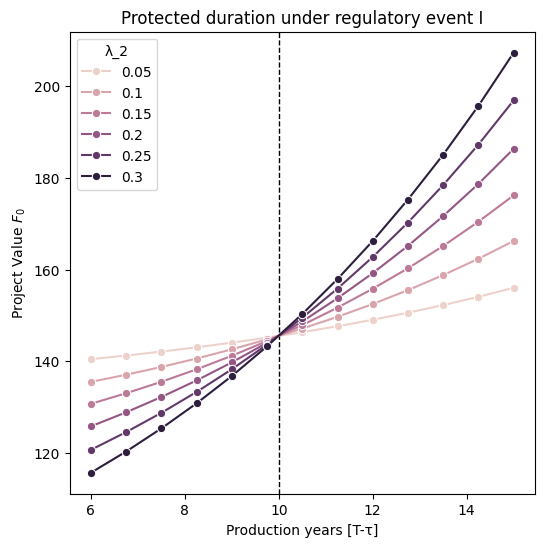

In [43]:
if RUN_SENSITIVITY:
    import pandas as pd
    # Vary the protected years available when regulatory event I occurs.
    YearRegulatory_values = np.linspace(-4, 5, 13) + 10
    lambda_2_values = np.linspace(0.05, 0.3, 6)
    results = []
    (n_simulations, T, dt, C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, lambda_1, lambda_2, tau_vs_tau3, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory) = init_sensitivity()
    TypeRegulatory = 'Duration'
    for YearRegulatory in YearRegulatory_values:
        for lambda_2 in lambda_2_values:
            (C, K1, K2, K3, t, tau_1, tau_2, tau_3) = simulate_paths(C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations)
            (F2, F0, regulatory, catastrophic, discontinued) = valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2)
            results.append({'Production years [T-τ]': YearRegulatory, 'λ_2': np.round(lambda_2, 2), 'Project Value [F0]': F0.mean() if F0.mean() > 0 else 0})
    results = pd.DataFrame(results)
    results
    slopes = {}
    import seaborn as sns
    plt.figure(figsize=(6, 6))
    plt.axvline(10, color='k', linestyle='--', linewidth=1)
    sns.lineplot(data=results, x='Production years [T-τ]', y='Project Value [F0]', hue='λ_2', marker='o')
    plt.ylabel('Project Value $F_0$')
    plt.title('Protected duration under regulatory event I')
    results.to_csv(OUT / 'event_I_duration.csv', index=False)
    display(results)
    plt.show()
else:
    print("Skipped optional sensitivity grid: Protected duration under regulatory event I.")


### Cash-flow fraction under regulatory event II

,Fraction of Cash flow,λ_2,Project Value [F0]
0,0.65,0.100,137.811280
1,0.65,0.175,132.255729
2,0.65,0.250,126.375181
3,0.65,0.325,120.610377
4,0.65,0.400,114.739154
5,0.70,0.100,138.912969
6,0.70,0.175,134.160107
7,0.70,0.250,129.112412
8,0.70,0.325,124.171095
9,0.70,0.400,119.122732


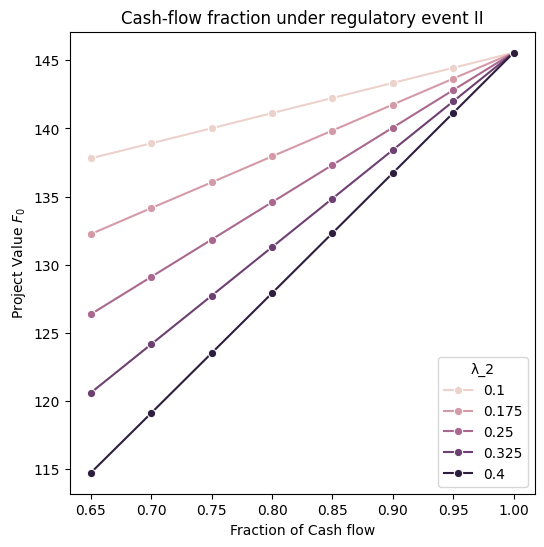

In [44]:
if RUN_SENSITIVITY:
    import pandas as pd
    # A fraction below one reduces cash flow; above one increases it.
    CashflowRedctionRegulatory_values = np.linspace(0.65, 1, 8)
    lambda_2_values = np.linspace(0.1, 0.4, 5)
    results = []
    (n_simulations, T, dt, C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, lambda_1, lambda_2, tau_vs_tau3, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory) = init_sensitivity()
    TypeRegulatory = 'Cashflow'
    for CashflowRedctionRegulatory in CashflowRedctionRegulatory_values:
        for lambda_2 in lambda_2_values:
            (C, K1, K2, K3, t, tau_1, tau_2, tau_3) = simulate_paths(C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations)
            (F2, F0, regulatory, catastrophic, discontinued) = valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2)
            results.append({'Fraction of Cash flow': CashflowRedctionRegulatory, 'λ_2': np.round(lambda_2, 3), 'Project Value [F0]': F0.mean()})
    results = pd.DataFrame(results)
    results
    import seaborn as sns
    plt.figure(figsize=(6, 6))
    sns.lineplot(data=results, x='Fraction of Cash flow', y='Project Value [F0]', hue='λ_2', marker='o')
    plt.ylabel('Project Value $F_0$')
    plt.title('Cash-flow fraction under regulatory event II')
    results.to_csv(OUT / 'event_II_fraction.csv', index=False)
    display(results)
    plt.show()
else:
    print("Skipped optional sensitivity grid: Cash-flow fraction under regulatory event II.")


## 5 Valuation isolines under regulatory changes

An isoline connects combinations of protected duration and retained cash flow with the same mean project value. This differs from a one-parameter sensitivity curve: both commercial terms vary together.

Set `RUN_ISOLINES=True` to evaluate a 13-by-10 grid spanning 7–15 protected years and cash-flow fractions from 0.6 to 1.5. Here `lambda_2=1`, so the specified commercial change applies to every project. Values above 1 represent a cash-flow increase. The plotted mean surface is floored at zero.


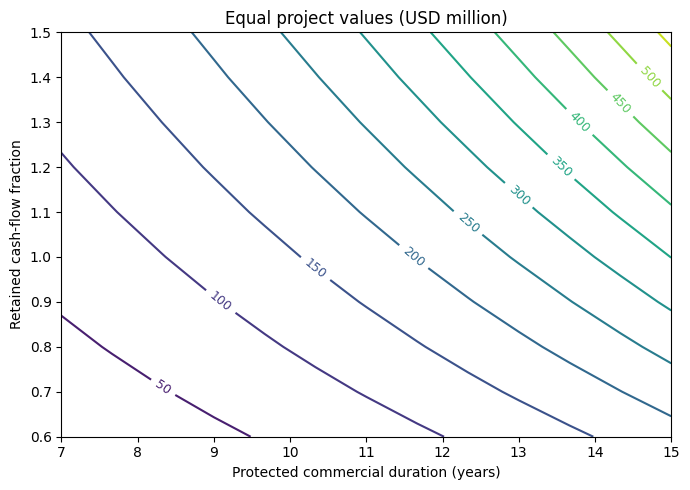

,YearPatent,CashflowRedctionRegulatory,F0
0,7.0,0.6,14.539882
1,7.0,0.7,27.227802
2,7.0,0.8,40.583166
3,7.0,0.9,54.174067
4,7.0,1.0,67.881232
...,...,...,...
125,15.0,1.1,393.156816
126,15.0,1.2,435.721881
127,15.0,1.3,478.260460
128,15.0,1.4,520.802762


In [46]:
if RUN_ISOLINES:
    import pandas as pd
    # Grid of protected durations for the two-dimensional equal-value surface.
    YearPatent_values = np.linspace(-6, 2, 13) + 13
    # A fraction below one reduces cash flow; above one increases it.
    CashflowRedctionRegulatory_values = np.linspace(0.6, 1.5, 10)
    results = []
    (n_simulations, T, dt, C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, lambda_1, lambda_2, tau_vs_tau3, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory) = init_sensitivity()
    TypeRegulatory = 'Cashflow'
    lambda_2 = 1
    for YearPatent in YearPatent_values:
        for CashflowRedctionRegulatory in CashflowRedctionRegulatory_values:
            (C, K1, K2, K3, t, tau_1, tau_2, tau_3) = simulate_paths(C0, K10, K20, K30, alpha_star_I, I1, I2, I3, sigma_C, sigma_K1, sigma_K2, sigma_K3, r, T, dt, n_simulations)
            (F2, F0, regulatory, catastrophic, discontinued) = valuation_procedure(K1, K2, K3, C, t, tau_1, tau_2, tau_3, tau_vs_tau3, dt, lambda_1, lambda_2, r, alpha_star_P, YearPatent, YearRegulatory, CashflowRedctionRegulatory, TypeRegulatory, Poly_deg=2)
            results.append({'YearPatent': YearPatent, 'CashflowRedctionRegulatory': CashflowRedctionRegulatory, 'F0': F0.mean() if F0.mean() > 0 else 0})
    results = pd.DataFrame(results)
    results
    
    results.to_csv(OUT/'valuation_isolines.csv',index=False)
    surface=results.pivot(index='CashflowRedctionRegulatory',columns='YearPatent',values='F0')
    fig,ax=plt.subplots(figsize=(7,5))
    contours=ax.contour(surface.columns.to_numpy(),surface.index.to_numpy(),surface.to_numpy(),levels=10)
    ax.clabel(contours,inline=True,fontsize=9)
    ax.set_xlabel('Protected commercial duration (years)');ax.set_ylabel('Retained cash-flow fraction')
    ax.set_title('Equal project values (USD million)')
    fig.tight_layout();fig.savefig(OUT/'valuation_isolines.png',dpi=160);plt.show()
    display(results)
else:
    print("Skipped optional valuation-isoline grid.")


## 6 Replication results

Replication call the simulation and valuation functions directly. They reset spending rates from `BASE` before each run. Run experiments serially because these functions share spending-rate globals and random-number state.

Each completed run is checkpointed. Cached results are reused only when parameters, computational code and recorded software versions match. Choose a new output directory after changing these settings. The first run uses seeds 42 and 50; later seed pairs come from `SeedSequence([20261105, replication])`. Equal seed indices across different grids do not produce nested or time-coupled paths.


In [ ]:
METRICS = ['mean','abandonment_rate','p05','p50','p95','p99','maximum','share_above_1bn','horizon_completion_share']


def seed_pair(rep):
    """Return reproducible development and event seeds for a replication index.

    Replication zero uses (42, 50); later indices produce deterministic seed
    pairs from SeedSequence. Both random streams change across replications.
    """
    if rep == 0: return 42,50
    return tuple(int(x) for x in np.random.SeedSequence([20261105,rep]).generate_state(2))


def per_step_failure(monthly_probability,dt):
    """Convert a monthly failure probability to a dt-year step probability.

    The conversion preserves survival over a year: (1-p_step)^(1/dt)
    equals (1-p_month)^12. Monthly dt returns the supplied probability exactly.
    """
    return monthly_probability if dt == 1/12 else -np.expm1(12*dt*np.log1p(-monthly_probability))


def run_one(rep,n,dt):
    """Simulate and value one uncapped base-case replication.

    Parameters are the replication index, number of paths and step size in years.
    Returns a dictionary of values, quantiles, event rates, seeds and diagnostics.
    The LSM policy is refitted in every run. Uses BASE and resets spending-rate
    globals; execution must be serial because the RNG and globals are shared.
    """
    global I1,I2,I3
    I1,I2,I3 = BASE['I1'],BASE['I2'],BASE['I3']
    path_seed,event_seed=seed_pair(rep)
    if n<2 or dt<=0 or not np.isclose(BASE['T']/dt,round(BASE['T']/dt)):
        raise ValueError('n must be >= 2; dt must divide T exactly.')
    p=BASE
    C,K1,K2,K3,t,t1,t2,t3=simulate_paths(p['C0'],p['K10'],p['K20'],p['K30'],p['alpha_star_I'],I1,I2,I3,p['sigma_C'],p['sigma_K1'],p['sigma_K2'],p['sigma_K3'],p['r'],p['T'],dt,n,seed=path_seed)
    for name,x in [('C',C),('K1',K1),('K2',K2),('K3',K3)]:
        if not np.isfinite(x).all():raise ValueError(f'Nonfinite simulation states in {name}')
    # The simulator uses the final date as the default completion time.
    # This diagnostic is a flag, not a correction of its terminal convention.
    horizon_share=np.mean(t3==t[-1])
    fail=per_step_failure(p['lambda_1'],dt)
    F2,F0,reg,cat,dis=valuation_procedure(K1,K2,K3,C,t,t1,t2,t3,p['tau_vs_tau3'],dt,fail,0.0,p['r'],p['alpha_star_P'],p['YearPatent'],p['YearRegulatory'],p['CashflowRedctionRegulatory'],p['TypeRegulatory'],Poly_deg=2,seed=event_seed)
    f=F0.ravel()
    if not np.isfinite(f).all():raise ValueError('Nonfinite final project values.')
    has_cat=cat.any(axis=1);has_dis=dis.any(axis=1)
    abandoned=has_dis & (~has_cat | (dis.argmax(axis=1)<=cat.argmax(axis=1)))
    q=np.quantile(f,[.05,.50,.95,.99])
    row=dict(replication=rep,n=n,dt=dt,steps_per_year=int(round(1/dt)),path_seed=path_seed,event_seed=event_seed,failure_probability_per_step=fail,
        mean=float(f.mean()),pathwise_mcse_descriptive=float(f.std(ddof=1)/np.sqrt(n)),abandonment_rate=float(abandoned.mean()),
        p05=q[0],p50=q[1],p95=q[2],p99=q[3],maximum=float(f.max()),share_above_1bn=float(np.mean(f>1000)),horizon_completion_share=float(horizon_share))
    del C,K1,K2,K3,F2,F0,reg,cat,dis;gc.collect()
    return row


def summarize(runs):
    """Summarize independent replications for each numerical specification.

    The between-run SD estimates variability of one simulation run. Dividing it
    by sqrt(R) gives the Monte Carlo SE of the R-run average. Student t intervals
    refer to that average, not to individual project outcomes. For maxima, the
    target is the expected sample maximum at the given N, not a population bound.
    """
    rows=[]
    for (n,steps),g in runs.groupby(['n','steps_per_year'],sort=False):
        for metric in METRICS:
            x=g[metric].to_numpy();R=len(x);sd=np.std(x,ddof=1) if R>1 else np.nan
            se=sd/np.sqrt(R);half=student_t.ppf(.975,R-1)*se if R>1 else np.nan
            rows.append(dict(n=n,steps_per_year=steps,metric=metric,replications=R,estimate=np.mean(x),single_run_mc_sd=sd,
                mcse_of_replication_average=se,ci95_low=np.mean(x)-half,ci95_high=np.mean(x)+half,
                min_across_seeds=np.min(x),median_across_seeds=np.median(x),max_across_seeds=np.max(x),
                relative_single_run_sd_pct=100*sd/abs(np.mean(x)) if np.mean(x)!=0 else np.nan))
    return pd.DataFrame(rows)


def convergence_differences(runs,reference_n=100000,reference_steps=12):
    """Compare each grid setting with the monthly 100,000-path reference.

    Match replication indices, compute within-pair differences and summarize
    them with Monte Carlo SEs and approximate t intervals. Seed indices are
    matched, but paths at different N or dt are not nested or time-coupled.
    """
    ref=runs[(runs.n==reference_n)&(runs.steps_per_year==reference_steps)]
    rows=[]
    for (n,steps),g in runs.groupby(['n','steps_per_year'],sort=False):
        if (n,steps)==(reference_n,reference_steps):continue
        both=g.merge(ref,on='replication',suffixes=('_test','_ref'))
        if len(both)<2:continue
        for metric in METRICS:
            d=both[metric+'_test']-both[metric+'_ref'];R=len(d);se=d.std(ddof=1)/np.sqrt(R);half=student_t.ppf(.975,R-1)*se
            rows.append(dict(n=n,steps_per_year=steps,reference_n=reference_n,reference_steps=reference_steps,metric=metric,paired_replications=R,
                difference=d.mean(),mcse_of_difference=se,ci95_low=d.mean()-half,ci95_high=d.mean()+half))
    return pd.DataFrame(rows)


def run_experiment(name,n_values=(100000,),steps_values=(12,),n_rep=20,output='monte_carlo_results',resume=True):
    """Run a grid of independent replications with checkpointed result tables.

    Choose path counts, steps per year, replication count and output directory.
    Matching cached runs are reused. A configuration/code check prevents mixing
    incompatible simulations. Returns run-level results, summary statistics and
    differences from the reference setting; also writes these tables to CSV.
    """
    if n_rep<2:raise ValueError('At least two replications are required.')
    out=Path(output);out.mkdir(parents=True,exist_ok=True)
    import inspect
    code=''.join(inspect.getsource(f) for f in (simulate_paths,valuation_procedure,Vtau3,PVcosts,run_one,seed_pair,per_step_failure))
    tree=ast.parse(code)
    for node in ast.walk(tree):
        if isinstance(node,(ast.FunctionDef,ast.AsyncFunctionDef)) and node.body and isinstance(node.body[0],ast.Expr) and isinstance(node.body[0].value,ast.Constant) and isinstance(node.body[0].value.value,str):
            node.body.pop(0)  # IPython normalizes docstring whitespace.
    cfg=dict(base=BASE,regulatory_probability=0,code_sha256=hashlib.sha256(ast.dump(tree).encode()).hexdigest(),
             seed_scheme='rep0=(42,50); others SeedSequence([20261105,rep])',python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__)
    config=out/'configuration.json'
    if config.exists() and resume:
        if json.loads(config.read_text())!=cfg:raise ValueError('Configuration/version changed: choose a new output directory.')
    config.write_text(json.dumps(cfg,indent=2))
    checkpoint=out/'all_runs.csv'
    rows=pd.read_csv(checkpoint).to_dict('records') if resume and checkpoint.exists() else []
    wanted=[]
    for n in n_values:
        for steps in steps_values:
            for rep in range(n_rep):
                key=(int(n),int(steps),rep);wanted.append(key)
                if any((int(x['n']),int(x['steps_per_year']),int(x['replication']))==key for x in rows):continue
                rows.append(run_one(rep,int(n),1/int(steps)))
                pd.DataFrame(rows).to_csv(checkpoint,index=False)
                print(f'{name}: N={n:,}, steps/year={steps}, replication {rep+1}/{n_rep}',flush=True)
    keys=set(wanted)
    selected=pd.DataFrame([x for x in rows if (int(x['n']),int(x['steps_per_year']),int(x['replication'])) in keys])
    selected.to_csv(out/f'{name}_runs.csv',index=False)
    summary=summarize(selected);summary.to_csv(out/f'{name}_summary.csv',index=False)
    differences=convergence_differences(selected)
    differences.to_csv(out/f'{name}_differences.csv',index=False)
    return selected,summary,differences


### 6.1 Independent random seeds and Monte Carlo uncertainty
The Monte Carlo experiments save each completed replication to CSV files. By default (resume=True), subsequent executions reuse compatible saved results and run only missing replications, avoiding unnecessary computation and allowing interrupted experiments to continue. 

To repeat all simulations, choose a new output folder or set resume=False, which replaces the existing checkpoint. Because random seeds are fixed, rerunning with the same settings and software environment should reproduce the same results.

- `single_run_mc_sd` is the observed SD of the statistic from one N-path run. 
- `mcse_of_replication_average` divides that SD by sqrt(R). The 95% Student t interval describes the across-replication average, not the uncertainty of one run. 
- For percentiles it concerns the expected finite-sample estimator, not a bias-corrected population quantile. 
- For maxima it concerns the expected sample maximum at that fixed N, not an upper bound on project value. 
- These t intervals are approximate, particularly for skewed sample maxima with only 20 replications

inspect the individual results and across-seed range as well.


In [ ]:
OUTPUT = 'results/monte_carlo'
N_BASE = 100_000
R_SEEDS = 20
seed_runs, seed_summary, _ = run_experiment(
    'seeds',
    n_values=(N_BASE,),
    steps_values=(12,),
    n_rep=R_SEEDS,
    output=OUTPUT,
    resume=True)
seed_summary[seed_summary.metric.isin(['mean','abandonment_rate','p05','p50','p95','p99','maximum'])]


seeds: N=100,000, steps/year=12, replication 1/20
seeds: N=100,000, steps/year=12, replication 2/20
seeds: N=100,000, steps/year=12, replication 3/20
seeds: N=100,000, steps/year=12, replication 4/20
seeds: N=100,000, steps/year=12, replication 5/20
seeds: N=100,000, steps/year=12, replication 6/20
seeds: N=100,000, steps/year=12, replication 7/20
seeds: N=100,000, steps/year=12, replication 8/20
seeds: N=100,000, steps/year=12, replication 9/20
seeds: N=100,000, steps/year=12, replication 10/20
seeds: N=100,000, steps/year=12, replication 11/20
seeds: N=100,000, steps/year=12, replication 12/20
seeds: N=100,000, steps/year=12, replication 13/20
seeds: N=100,000, steps/year=12, replication 14/20
seeds: N=100,000, steps/year=12, replication 15/20
seeds: N=100,000, steps/year=12, replication 16/20
seeds: N=100,000, steps/year=12, replication 17/20
seeds: N=100,000, steps/year=12, replication 18/20
seeds: N=100,000, steps/year=12, replication 19/20
seeds: N=100,000, steps/year=12, replica

,n,steps_per_year,metric,replications,estimate,single_run_mc_sd,mcse_of_replication_average,ci95_low,ci95_high,min_across_seeds,median_across_seeds,max_across_seeds,relative_single_run_sd_pct
0,100000,12,mean,20,146.862529,1.537947,0.343895,146.142748,147.582311,144.847192,146.301628,150.137216,1.047202
1,100000,12,abandonment_rate,20,0.024870,0.003006,0.000672,0.023463,0.026277,0.016070,0.025170,0.028960,12.086567
2,100000,12,p05,20,-108.782331,0.715281,0.159942,-109.117093,-108.447569,-110.874032,-108.835693,-107.720186,0.657535
3,100000,12,p50,20,-10.712890,0.276971,0.061933,-10.842516,-10.583263,-11.166253,-10.561288,-10.485674,2.585397
4,100000,12,p95,20,893.776437,6.623051,1.480959,890.676754,896.876120,880.276376,894.034699,907.571026,0.741019
5,100000,12,p99,20,1852.120078,22.599224,5.053340,1841.543315,1862.696840,1810.482747,1849.076430,1906.324473,1.220181
6,100000,12,maximum,20,15605.204552,6065.284449,1356.238833,12766.564051,18443.845053,9843.829535,13602.600782,35299.846553,38.867061


In [ ]:
# Individual seeds show whether maxima or tail estimates are unstable.
seed_runs[['replication','path_seed','event_seed','mean','abandonment_rate','p05','p50','p95','p99','maximum','horizon_completion_share']]


,replication,path_seed,event_seed,mean,abandonment_rate,p05,p50,p95,p99,maximum,horizon_completion_share
0,0,42,50,145.558034,0.02393,-109.348007,-10.485674,881.615477,1848.644020,21982.472879,0.00006
1,1,3167503844,3664493812,146.983760,0.02648,-108.834108,-10.636903,892.071426,1850.616154,12483.838124,0.00009
2,2,872538121,1307180798,145.773362,0.02414,-109.150588,-11.166253,895.450174,1835.861319,9843.829535,0.00007
3,3,3244746832,2784998069,145.832971,0.02005,-109.302729,-10.485674,892.855854,1810.482747,22326.272427,0.00003
4,4,2719986288,3764099574,145.701582,0.02371,-108.948495,-11.166253,889.581548,1833.762960,12198.907582,0.00005
5,5,2348468951,3722088921,145.762785,0.02410,-108.523456,-10.485674,890.391883,1828.048623,10337.674309,0.00012
6,6,993344092,2223532022,150.137216,0.02504,-108.837278,-10.485674,907.571026,1906.324473,22179.601968,0.00005
7,7,304532973,519410788,147.223332,0.02839,-108.289155,-10.485674,894.818339,1861.365813,11974.122596,0.00008
8,8,3666692590,1337522327,146.073965,0.02320,-109.161728,-10.485674,891.221647,1842.770629,14896.442324,0.00006
9,9,1078689913,1502900231,149.340713,0.02682,-108.465538,-10.987575,897.610277,1897.838007,13224.214140,0.00003


### 6.2 Convergence with the number of paths
Compare 10,000, 25,000, 50,000, 100,000 and 200,000 paths at monthly steps. 

Defaults use 5 replications per setting as an initial run. Increase for precise comparisons. 

Differences are calculated relative to 100,000 paths using the same replication indices. 

In [ ]:
RUN_PATH_COUNTS = True  # Set True to execute this additional experiment.
R_CONVERGENCE = 5
if RUN_PATH_COUNTS:
    path_runs, path_summary, path_differences = run_experiment('path_counts', n_values=(10_000,25_000,50_000,100_000,200_000), steps_values=(12,), n_rep=R_CONVERGENCE, output=OUTPUT)
    # summary metrics are means across replications
    display(path_summary[path_summary.metric.isin(['mean','abandonment_rate','p05','p50','p95','p99','maximum'])])


,n,steps_per_year,metric,replications,estimate,single_run_mc_sd,mcse_of_replication_average,ci95_low,ci95_high,min_across_seeds,median_across_seeds,max_across_seeds,relative_single_run_sd_pct
0,100000,12,mean,5,145.969942,0.575959,0.257577,145.254793,146.685090,145.558034,145.773362,146.983760,0.394574
1,100000,12,abandonment_rate,5,0.023662,0.002307,0.001032,0.020797,0.026527,0.020050,0.023930,0.026480,9.750104
2,100000,12,p05,5,-109.116785,0.222154,0.099350,-109.392626,-108.840945,-109.348007,-109.150588,-108.834108,0.203593
3,100000,12,p50,5,-10.788151,0.350636,0.156809,-11.223524,-10.352779,-11.166253,-10.636903,-10.485674,3.250199
4,100000,12,p95,5,890.314896,5.294588,2.367812,883.740797,896.888995,881.615477,892.071426,895.450174,0.594687
5,100000,12,p99,5,1835.873440,16.043510,7.174876,1815.952791,1855.794089,1810.482747,1835.861319,1850.616154,0.873890
6,100000,12,maximum,5,15767.064109,5921.371075,2648.117649,8414.710825,23119.417393,9843.829535,12483.838124,22326.272427,37.555318
9,10000,12,mean,5,144.149602,1.431283,0.640089,142.372428,145.926775,142.618068,144.467513,146.107997,0.992915
10,10000,12,abandonment_rate,5,0.025980,0.001883,0.000842,0.023642,0.028318,0.022900,0.026800,0.027500,7.249223
11,10000,12,p05,5,-108.676627,2.061339,0.921859,-111.236117,-106.117136,-111.861350,-107.706932,-106.964786,1.896764
